In [19]:
!pip install -q numpy pandas matplotlib seaborn

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from collections import defaultdict

random.seed(42)
np.random.seed(42)

print("All libraries imported successfully.")

All libraries imported successfully.


# Environment Design

In [21]:
GRID_SIZE = 8

# Rescue agent starting positions
START_POSITIONS = [(0, 0), (7, 7)]

# Victim locations
VICTIMS = [(0, 6), (2, 3), (5, 6), (7, 2)]

# Obstacles
OBSTACLES = {
    (1, 1), (1, 2), (2, 1),
    (3, 4), (4, 4),
    (5, 1), (5, 2), (6, 5)
}

# Hazardous areas
HAZARDS = {
    (2, 5), (3, 5), (5, 5), (6, 2)
}

print("Grid Environment Created")
print("Grid Size:", GRID_SIZE, "x", GRID_SIZE)
print("Rescue Agents:", len(START_POSITIONS))
print("Victims:", len(VICTIMS))
print("Obstacles:", len(OBSTACLES))
print("Hazards:", len(HAZARDS))

Grid Environment Created
Grid Size: 8 x 8
Rescue Agents: 2
Victims: 4
Obstacles: 8
Hazards: 4


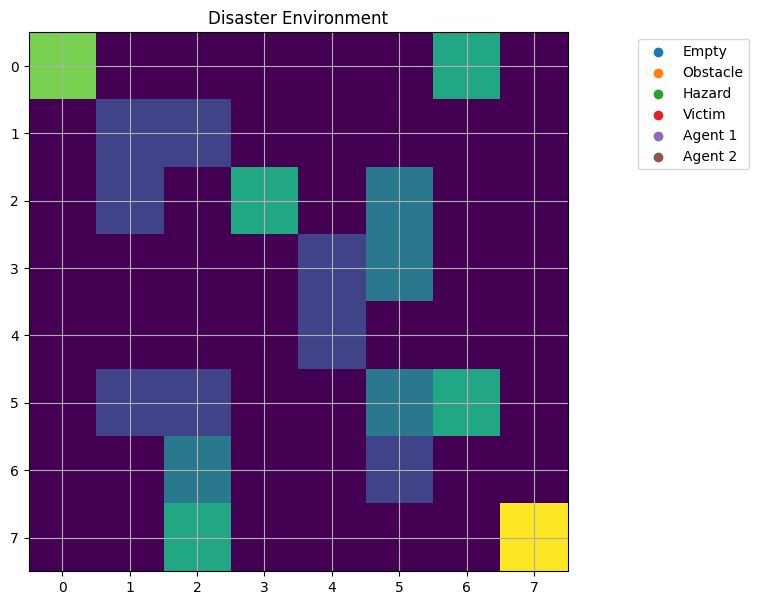

In [22]:
def visualize_grid(agent_positions, victims, title="Disaster Environment"):

    grid = np.zeros((GRID_SIZE, GRID_SIZE))

    for x, y in OBSTACLES:
        grid[x, y] = 1

    for x, y in HAZARDS:
        grid[x, y] = 2

    for x, y in victims:
        grid[x, y] = 3

    for i, (x, y) in enumerate(agent_positions):
        grid[x, y] = 4 + i

    plt.figure(figsize=(7, 7))
    plt.imshow(grid, cmap="viridis", vmin=0, vmax=5)

    plt.xticks(range(GRID_SIZE))
    plt.yticks(range(GRID_SIZE))
    plt.grid(True)

    labels = {
        0: "Empty",
        1: "Obstacle",
        2: "Hazard",
        3: "Victim",
        4: "Agent 1",
        5: "Agent 2"
    }

    for value, label in labels.items():
        plt.scatter([], [], label=label)

    plt.legend(bbox_to_anchor=(1.35, 1))
    plt.title(title)
    plt.show()


visualize_grid(START_POSITIONS, VICTIMS)

# States, Actions and Rewards

In [23]:
ACTIONS = {
    0: (-1, 0),  # Up
    1: (1, 0),   # Down
    2: (0, -1),  # Left
    3: (0, 1),   # Right
    4: (0, 0)    # Stay
}

ACTION_NAMES = ["Up", "Down", "Left", "Right", "Stay"]


class RescueEnvironment:

    def reset(self):
        self.agent_positions = list(START_POSITIONS)
        self.victims = set(VICTIMS)
        self.collisions = 0
        self.rescued = 0

        return self.agent_positions

    def get_state(self, agent_id):
        position = self.agent_positions[agent_id]
        other_position = self.agent_positions[1 - agent_id]

        if self.victims:
            target = min(
                self.victims,
                key=lambda v: abs(position[0] - v[0]) +
                              abs(position[1] - v[1])
            )
        else:
            target = (-1, -1)

        return (position, target, other_position)

    def step(self, agent_id, action):
        x, y = self.agent_positions[agent_id]
        dx, dy = ACTIONS[action]

        new_position = (x + dx, y + dy)
        reward = -1

        # Check boundaries and obstacles
        invalid_move = (
            not (0 <= new_position[0] < GRID_SIZE and
                 0 <= new_position[1] < GRID_SIZE)
            or new_position in OBSTACLES
        )

        if invalid_move:
            reward = -6
            self.collisions += 1

        # Check collision with another agent
        elif new_position == self.agent_positions[1 - agent_id]:
            reward = -10
            self.collisions += 1

        else:
            self.agent_positions[agent_id] = new_position

            # Apply hazard penalty
            if new_position in HAZARDS:
                reward -= 5

            # Rescue victim
            if new_position in self.victims:
                self.victims.remove(new_position)
                self.rescued += 1
                reward += 30

            # Penalize unnecessary waiting
            if action == 4:
                reward -= 2

        done = len(self.victims) == 0

        return reward, done


env = RescueEnvironment()
env.reset()

print("Environment initialized successfully.")
print("Initial States:")

for i in range(2):
    print(f"Agent {i + 1}: {env.get_state(i)}")

Environment initialized successfully.
Initial States:
Agent 1: ((0, 0), (2, 3), (7, 7))
Agent 2: ((7, 7), (5, 6), (0, 0))


In [25]:
REWARDS = {
    "rescue": 30,
    "movement": -1,
    "obstacle_collision": -6,
    "agent_collision": -10,
    "hazard": -5,
    "unnecessary_stay": -2
}

print("Reward system configured:")
for event, reward in REWARDS.items():
    print(event, ":", reward)

Reward system configured:
rescue : 30
movement : -1
obstacle_collision : -6
agent_collision : -10
hazard : -5
unnecessary_stay : -2


#Independent Q-Learning

In [26]:
LEARNING_RATE = 0.1
DISCOUNT_FACTOR = 0.9

EPSILON = 1.0
EPSILON_DECAY = 0.995
MIN_EPSILON = 0.05

EPISODES = 1200
MAX_STEPS = 100

# Independent Q-table for each agent
independent_q = [
    defaultdict(lambda: np.zeros(len(ACTIONS)))
    for _ in range(2)
]

print("Independent Q-tables initialized successfully.")

Independent Q-tables initialized successfully.


In [27]:
def choose_action(q_table, state, epsilon):

    if random.random() < epsilon:
        return random.randrange(len(ACTIONS))

    values = q_table[state]

    best_actions = np.flatnonzero(
        values == np.max(values)
    )

    return int(random.choice(best_actions))


def train_independent():

    env = RescueEnvironment()
    epsilon = EPSILON

    reward_history = []
    rescue_history = []

    for episode in range(EPISODES):

        env.reset()
        episode_reward = 0

        for step in range(MAX_STEPS):

            for agent_id in range(2):

                if not env.victims:
                    break

                state = env.get_state(agent_id)

                action = choose_action(
                    independent_q[agent_id],
                    state, epsilon
                )

                reward, done = env.step(agent_id, action)

                next_state = env.get_state(agent_id)

                old_value = independent_q[agent_id][state][action]

                next_value = np.max(
                    independent_q[agent_id][next_state]
                )

                target = reward

                if not done:
                    target += DISCOUNT_FACTOR * next_value

                independent_q[agent_id][state][action] = (
                    old_value + LEARNING_RATE *
                    (target - old_value)
                )

                episode_reward += reward

                if done:
                    break

            if not env.victims:
                break

        epsilon = max(
            MIN_EPSILON,
            epsilon * EPSILON_DECAY
        )

        reward_history.append(episode_reward)
        rescue_history.append(env.rescued)

        if (episode + 1) % 200 == 0:
            print(
                f"Episode {episode + 1}/{EPISODES} | "
                f"Reward: {episode_reward} | "
                f"Rescued: {env.rescued}"
            )

    return reward_history, rescue_history


print("Independent Q-learning function created.")

Independent Q-learning function created.


#Cooperative Learning

In [28]:
# One shared Q-table used by both rescue agents
cooperative_q = defaultdict(
    lambda: np.zeros(len(ACTIONS))
)

print("Shared cooperative Q-table initialized successfully.")

Shared cooperative Q-table initialized successfully.


In [30]:
def train_cooperative():

    env = RescueEnvironment()
    epsilon = EPSILON

    reward_history = []
    rescue_history = []

    for episode in range(EPISODES):

        env.reset()
        episode_reward = 0

        for step in range(MAX_STEPS):

            for agent_id in range(2):

                if not env.victims:
                    break

                state = env.get_state(agent_id)

                # Select action using shared Q-table
                action = choose_action(
                    cooperative_q,
                    state,
                    epsilon
                )

                # Execute action and receive team reward
                team_reward, done = env.step(
                    agent_id,
                    action
                )

                next_state = env.get_state(agent_id)

                # Q-learning update
                old_value = cooperative_q[state][action]
                next_value = np.max(cooperative_q[next_state])

                target = team_reward

                if not done:
                    target += DISCOUNT_FACTOR * next_value

                cooperative_q[state][action] = (
                    old_value + LEARNING_RATE *
                    (target - old_value)
                )

                episode_reward += team_reward

                if done:
                    break

            if not env.victims:
                break

        # Reduce exploration over time
        epsilon = max(
            MIN_EPSILON,
            epsilon * EPSILON_DECAY
        )

        reward_history.append(episode_reward)
        rescue_history.append(env.rescued)

        if (episode + 1) % 200 == 0:
            print(
                f"Episode {episode + 1}/{EPISODES} | "
                f"Team Reward: {episode_reward} | "
                f"Rescued: {env.rescued}"
            )

    return reward_history, rescue_history


print("Cooperative Q-learning function created successfully.")

Cooperative Q-learning function created successfully.


In [31]:
print("Training Independent Q-Learning...")

independent_rewards, independent_rescues = (
    train_independent()
)

print("\nTraining Cooperative Q-Learning...")

cooperative_rewards, cooperative_rescues = (
    train_cooperative()
)

print("\nBoth training processes completed.")

Training Independent Q-Learning...
Episode 200/1200 | Reward: -446 | Rescued: 3
Episode 400/1200 | Reward: -275 | Rescued: 3
Episode 600/1200 | Reward: -180 | Rescued: 3
Episode 800/1200 | Reward: 11 | Rescued: 4
Episode 1000/1200 | Reward: -68 | Rescued: 4
Episode 1200/1200 | Reward: 19 | Rescued: 4

Training Cooperative Q-Learning...
Episode 200/1200 | Team Reward: -317 | Rescued: 4
Episode 400/1200 | Team Reward: 9 | Rescued: 4
Episode 600/1200 | Team Reward: -99 | Rescued: 4
Episode 800/1200 | Team Reward: 21 | Rescued: 4
Episode 1000/1200 | Team Reward: -22 | Rescued: 4
Episode 1200/1200 | Team Reward: 73 | Rescued: 4

Both training processes completed.


#Visualization

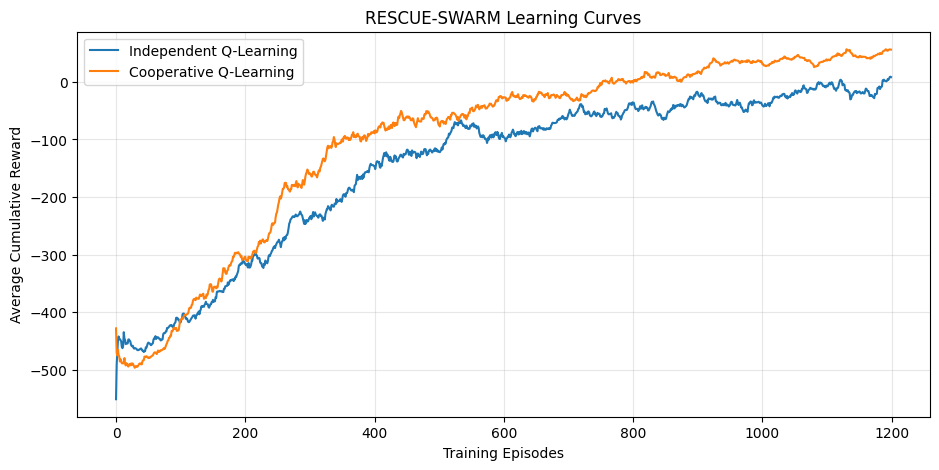

In [32]:
def moving_average(values, window=50):

    return pd.Series(values).rolling(
        window=window, min_periods=1
    ).mean()


plt.figure(figsize=(11, 5))

plt.plot(
    moving_average(independent_rewards),
    label="Independent Q-Learning"
)

plt.plot(
    moving_average(cooperative_rewards),
    label="Cooperative Q-Learning"
)

plt.xlabel("Training Episodes")
plt.ylabel("Average Cumulative Reward")
plt.title("RESCUE-SWARM Learning Curves")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

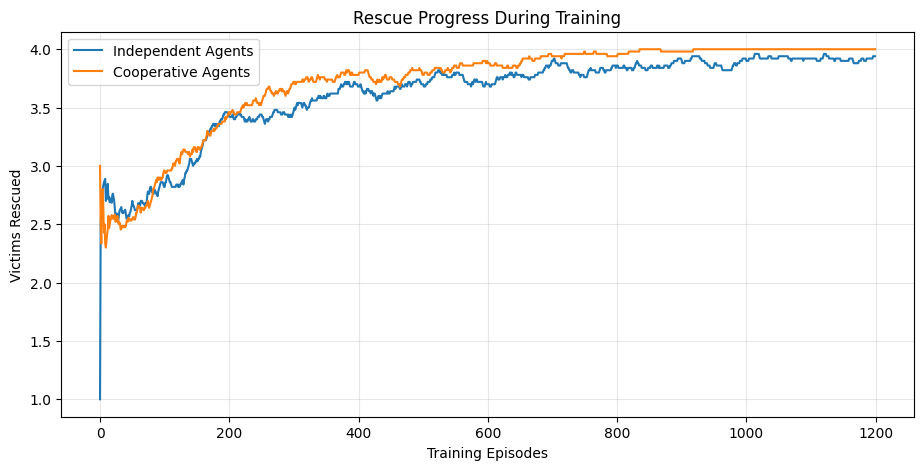

In [33]:
plt.figure(figsize=(11, 5))

plt.plot(
    moving_average(independent_rescues),
    label="Independent Agents"
)

plt.plot(
    moving_average(cooperative_rescues),
    label="Cooperative Agents"
)

plt.xlabel("Training Episodes")
plt.ylabel("Victims Rescued")
plt.title("Rescue Progress During Training")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

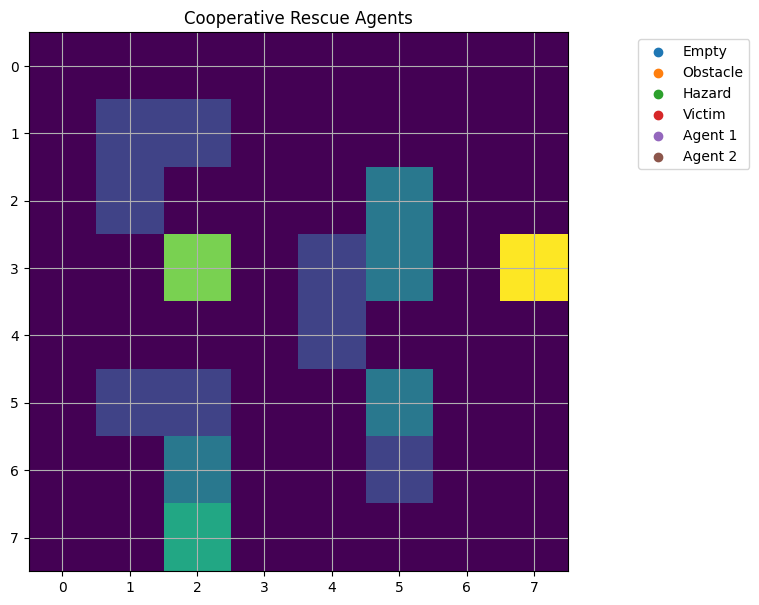

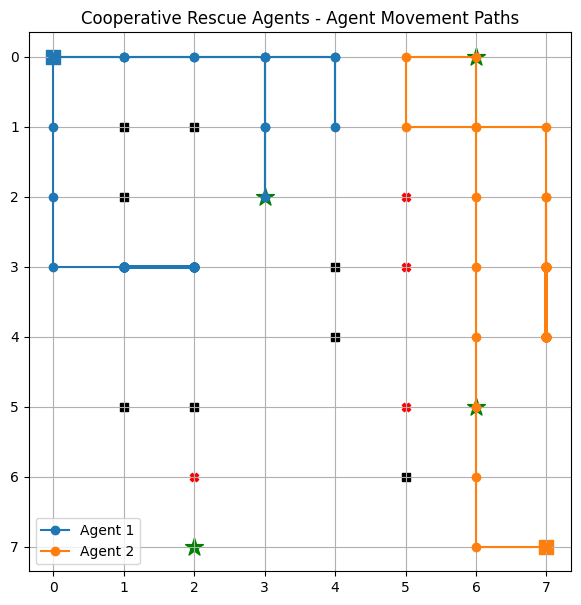

Victims Rescued: 3
Collisions: 1


In [34]:
def visualize_learned_path(q_table, title):

    env = RescueEnvironment()
    env.reset()

    paths = [
        [env.agent_positions[0]],
        [env.agent_positions[1]]
    ]

    for step in range(MAX_STEPS):

        for agent_id in range(2):

            if not env.victims:
                break

            state = env.get_state(agent_id)

            action = choose_action(q_table, state, 0)

            env.step(agent_id, action)

            paths[agent_id].append(
                env.agent_positions[agent_id]
            )

        if not env.victims:
            break

    visualize_grid(
        env.agent_positions,
        env.victims,
        title
    )

    plt.figure(figsize=(7, 7))

    for x, y in OBSTACLES:
        plt.scatter(y, x, marker="s", color="black")

    for x, y in HAZARDS:
        plt.scatter(y, x, marker="X", color="red")

    for i, path in enumerate(paths):
        px = [p[1] for p in path]
        py = [p[0] for p in path]

        plt.plot(px, py, marker="o", label=f"Agent {i+1}")

        plt.scatter(
            px[0], py[0], marker="s", s=100
        )

    for x, y in VICTIMS:
        plt.scatter(y, x, marker="*", s=180, color="green")

    plt.xticks(range(GRID_SIZE))
    plt.yticks(range(GRID_SIZE))
    plt.grid()
    plt.gca().invert_yaxis()
    plt.legend()
    plt.title(title + " - Agent Movement Paths")
    plt.show()

    print("Victims Rescued:", env.rescued)
    print("Collisions:", env.collisions)


visualize_learned_path(
    cooperative_q,
    "Cooperative Rescue Agents"
)

#Performance Evaluation

In [36]:
def evaluate_agents(mode, episodes=30):

    env = RescueEnvironment()
    results = []

    for episode in range(episodes):

        env.reset()

        total_reward = 0
        total_actions = 0
        completion_time = MAX_STEPS * 2

        for step in range(MAX_STEPS):

            for agent_id in range(2):

                if not env.victims:
                    break

                state = env.get_state(agent_id)

                # Select the appropriate Q-table
                if mode == "Independent":
                    q_table = independent_q[agent_id]
                else:
                    q_table = cooperative_q

                # Greedy action selection
                action = choose_action(q_table, state, 0)

                reward, done = env.step(agent_id, action)

                total_reward += reward
                total_actions += 1

                if done:
                    completion_time = total_actions
                    break

            if not env.victims:
                break

        results.append({
            "Successful Rescues": env.rescued,
            "Completion Time": completion_time,
            "Cumulative Reward": total_reward,
            "Collisions": env.collisions
        })

    return pd.DataFrame(results)


# Evaluate both approaches
independent_results = evaluate_agents("Independent")
cooperative_results = evaluate_agents("Cooperative")

print("Evaluation completed successfully.")

Evaluation completed successfully.


In [37]:
comparison = pd.DataFrame({
    "Metric": [
        "Successful Rescues",
        "Completion Time",
        "Cumulative Reward",
        "Collisions"
    ],

    "Independent Q-Learning": [
        independent_results["Successful Rescues"].mean(),
        independent_results["Completion Time"].mean(),
        independent_results["Cumulative Reward"].mean(),
        independent_results["Collisions"].mean()
    ],

    "Cooperative Q-Learning": [
        cooperative_results["Successful Rescues"].mean(),
        cooperative_results["Completion Time"].mean(),
        cooperative_results["Cumulative Reward"].mean(),
        cooperative_results["Collisions"].mean()
    ]
})

display(comparison.round(2))

,Metric,Independent Q-Learning,Cooperative Q-Learning
0,Successful Rescues,4.0,3.0
1,Completion Time,33.0,200.0
2,Cumulative Reward,87.0,-115.0
3,Collisions,0.0,1.0


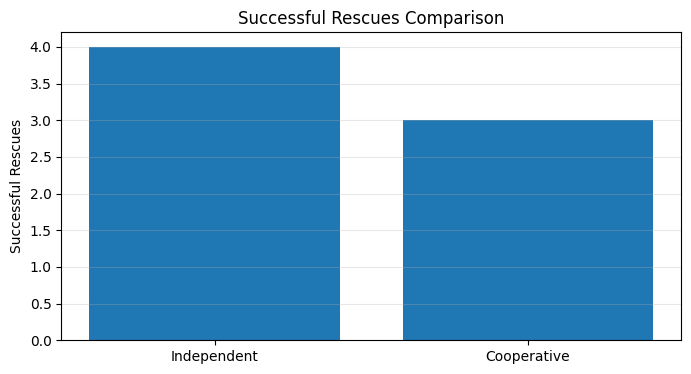

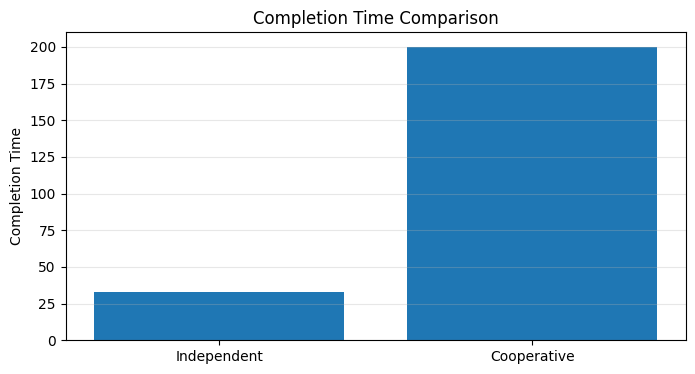

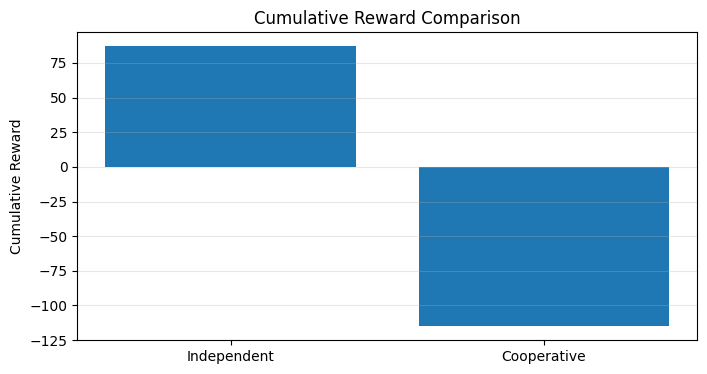

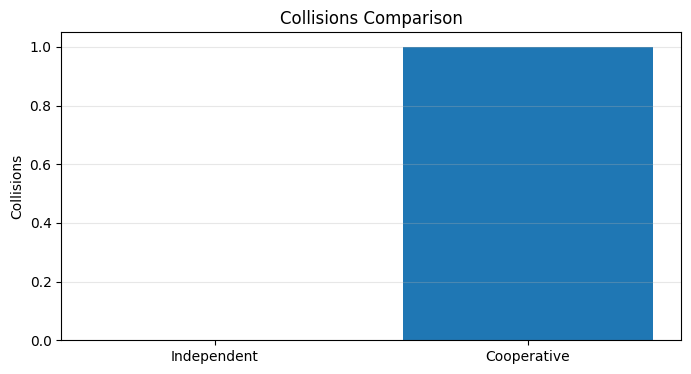

In [38]:
metrics = [
    "Successful Rescues",
    "Completion Time",
    "Cumulative Reward",
    "Collisions"
]

for metric in metrics:

    plt.figure(figsize=(8, 4))

    plt.bar(
        ["Independent", "Cooperative"],
        [
            comparison.loc[
                comparison["Metric"] == metric,
                "Independent Q-Learning"
            ].iloc[0],

            comparison.loc[
                comparison["Metric"] == metric,
                "Cooperative Q-Learning"
            ].iloc[0]
        ]
    )

    plt.title(metric + " Comparison")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

In [39]:
print("=" * 55)
print("PROJECT RESCUE-SWARM - FINAL REPORT")
print("=" * 55)

print("\nINDEPENDENT Q-LEARNING")
print(independent_results.mean().round(2))

print("\nCOOPERATIVE Q-LEARNING")
print(cooperative_results.mean().round(2))

print("\nEXPERIMENT SUMMARY")
print("-" * 55)

print("Total Agents:", len(START_POSITIONS))
print("Total Victims:", len(VICTIMS))
print("Training Episodes:", EPISODES)
print("Evaluation Episodes:", len(independent_results))

print("\nExperiment completed successfully.")

PROJECT RESCUE-SWARM - FINAL REPORT

INDEPENDENT Q-LEARNING
Successful Rescues     4.0
Completion Time       33.0
Cumulative Reward     87.0
Collisions             0.0
dtype: float64

COOPERATIVE Q-LEARNING
Successful Rescues      3.0
Completion Time       200.0
Cumulative Reward    -115.0
Collisions              1.0
dtype: float64

EXPERIMENT SUMMARY
-------------------------------------------------------
Total Agents: 2
Total Victims: 4
Training Episodes: 1200
Evaluation Episodes: 30

Experiment completed successfully.
